# Load dataset

In [1]:
import pandas as pd

pd.set_option("display.max_columns", None)

file_id = "1jVzIRp6zxrGVDXRtuG-8mc6CzHrbQFED"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(
    url,
    parse_dates=["started_at"],
    dtype={"y_overdue": "boolean", "prev_late": "boolean"},
)

KEYS = ["id", "started_at", "customer_id", "client_id"]
TARGETS = ["y_overdue", "y_lost"]
NUM = ["hour", "month", "plan_hours", "n_batteries", "deposit_amount", "price_total",
       "prepaid_share", "client_prev_rentals", "client_prev_late_rate", "client_prev_lost",
       "days_since_prev"]
CAT = ["tenant", "dow", "model", "deposit_kind", "client_residency", "issued_by_employee_id"]
BOOL = ["is_weekend", "block_missing", "first_visit", "prev_late"]
df.head()

,id,started_at,customer_id,client_id,tenant,hour,dow,month,is_weekend,plan_hours,n_batteries,model,deposit_kind,deposit_amount,price_total,prepaid_share,client_residency,block_missing,issued_by_employee_id,first_visit,client_prev_rentals,client_prev_late_rate,client_prev_lost,prev_late,days_since_prev,y_overdue,y_lost
0,65f0da3c-7abb-4f9c-b2b7-1968b8a663e2,2025-01-18 12:19:51+00:00,2975e970-5ed2-46f0-b809-f455e9873912,01d32244-c1b4-4a1a-97c1-b414ab17aa69,synth-a,15,5,1,True,72.000000,1,Trail 350,document,NaN,5720.0,0.0,local,False,23b8c1e9-3924-46de-beb1-3b9046685257,True,0,NaN,0,<NA>,NaN,False,False
1,9dddd117-7806-49e8-9857-f0891492517a,2025-01-18 13:01:54+00:00,e5ceac23-aff7-488d-aada-d07f2d6b89e7,662e7ea7-9c74-4faf-8fed-aa3b52e3b310,synth-a,16,5,1,True,2.000000,2,Cargo 500,cash,2000.0,870.0,0.0,local,False,17fc695a-07a0-4a6e-8822-e8f36c031199,False,2,NaN,0,<NA>,7.291227,False,False
2,5f2c2c26-7b12-4db4-a509-1af3c7a9b788,2025-01-18 14:32:11+00:00,3bd8a8e5-feaf-47c1-9ff9-6ac8294b1d6f,53028b18-d032-4689-8dd3-b231402c1e98,synth-a,17,5,1,True,2.000000,1,Cargo 500,document,NaN,NaN,NaN,local,False,8fadc1a6-06cb-4fb3-9a1d-e644815ef6d1,False,1,NaN,0,<NA>,19.314884,False,False
3,e9a9ea82-7552-46e3-abd2-277e49bae976,2025-01-18 14:58:59+00:00,ef4e31fe-b93b-4061-95bd-125ecfdc8f7b,918eade9-dbd4-44b9-89d6-158602d45aad,synth-c,16,5,1,True,4.016944,2,Cargo 500,NaN,NaN,NaN,NaN,NaN,True,6e996e3e-e3b1-47fc-8a34-50fc9918ee46,True,0,NaN,0,<NA>,NaN,False,False
4,2a036585-d898-484e-834d-216eb0b615c0,2025-01-18 15:12:19+00:00,d3497354-5320-4fc3-9f36-8a17065f8f69,7626e160-db24-44cb-85aa-e5ca667d6f8e,synth-b,20,5,1,True,0.794722,1,Urban 250,NaN,NaN,NaN,NaN,NaN,True,50f0fd0a-750c-4b75-8ccc-9bc2a53f8a28,True,0,NaN,0,<NA>,NaN,True,False


# EDA

In [2]:
df.describe()

,hour,dow,month,plan_hours,n_batteries,deposit_amount,price_total,prepaid_share,client_prev_rentals,client_prev_late_rate,client_prev_lost,days_since_prev
count,39344.000000,39344.000000,39344.000000,39344.000000,39344.000000,6836.00000,21490.000000,19358.000000,39344.000000,23384.000000,39344.0,23711.000000
mean,12.291734,3.126703,6.571421,21.580956,1.303070,2727.61849,2245.196370,0.549799,2.110436,0.082659,0.0,13.401769
std,3.328721,2.028164,2.813368,38.387186,0.459591,1461.76961,2774.688965,0.445396,2.877998,0.208218,0.0,12.748747
min,9.000000,0.000000,1.000000,0.002778,1.000000,1000.00000,270.000000,0.000000,0.000000,0.000000,0.0,0.296829
25%,9.000000,1.000000,5.000000,2.000000,1.000000,2000.00000,890.000000,0.000000,0.000000,0.000000,0.0,5.623547
50%,12.000000,3.000000,7.000000,4.000000,1.000000,2000.00000,1440.000000,0.500000,1.000000,0.000000,0.0,9.817512
75%,15.000000,5.000000,9.000000,24.000000,2.000000,3000.00000,2210.000000,1.000000,3.000000,0.000000,0.0,16.937859
max,20.000000,6.000000,12.000000,168.000000,2.000000,5000.00000,17320.000000,1.000000,26.000000,1.000000,0.0,315.135579


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39344 entries, 0 to 39343
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   id                     39344 non-null  str                
 1   started_at             39344 non-null  datetime64[us, UTC]
 2   customer_id            39344 non-null  str                
 3   client_id              39344 non-null  str                
 4   tenant                 39344 non-null  str                
 5   hour                   39344 non-null  int64              
 6   dow                    39344 non-null  int64              
 7   month                  39344 non-null  int64              
 8   is_weekend             39344 non-null  bool               
 9   plan_hours             39344 non-null  float64            
 10  n_batteries            39344 non-null  int64              
 11  model                  39344 non-null  str                
 12  d

## 0. Scope: overdue only

Target: `y_overdue` — the bike came back more than 15 minutes after `due_at`.

Lost checkouts (`y_lost`) have no overdue label (`y_overdue` is empty) and are excluded. Losses are
~1% of checkouts (~390 cases): too few for a model of their own, and in practice they are handled by
the deposit policy rather than by a model.

The data is synthetic, so the patterns below are the ones built into the generator. The goal of this
EDA is to check the data and decide how to prepare it for the model.

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score, roc_auc_score

data = df[df["y_overdue"].notna()].copy()
data["y"] = data["y_overdue"].astype(int)
FEATURES = NUM + CAT + BOOL
print(f"checkouts: {len(df)}, lost (excluded): {len(df) - len(data)}, used: {len(data)}")
print(f"overdue rate: {data['y'].mean():.2%} ({data['y'].sum()} of {len(data)})")


def rate_by(col, data=data):
    """Overdue rate per group with its standard error."""
    out = data.groupby(col, dropna=False, observed=True)["y"].agg(rate="mean", n="count")
    out["se"] = (out["rate"] * (1 - out["rate"]) / out["n"]) ** 0.5
    return out.sort_values("rate", ascending=False).round(4)

checkouts: 39344, lost (excluded): 391, used: 38953
overdue rate: 8.29% (3229 of 38953)


## 1. Data quality and value ranges

In [5]:
print("duplicate ids:", data["id"].duplicated().sum())
print("period:", data["started_at"].min(), "—", data["started_at"].max())
print("constant columns:", [c for c in FEATURES if data[c].nunique(dropna=False) == 1])
data[NUM].describe().T

duplicate ids: 0
period: 2025-01-18 12:19:51+00:00 — 2026-09-30 18:59:22+00:00
constant columns: ['client_prev_lost']


,count,mean,std,min,25%,50%,75%,max
hour,38953.0,12.290504,3.331980,9.000000,9.000000,12.000000,15.000000,20.000000
month,38953.0,6.571715,2.813073,1.000000,5.000000,7.000000,9.000000,12.000000
plan_hours,38953.0,21.441388,38.225681,0.002778,2.000000,4.000000,24.000000,168.000000
n_batteries,38953.0,1.303212,0.459652,1.000000,1.000000,1.000000,2.000000,2.000000
deposit_amount,6806.0,2726.417867,1461.561879,1000.000000,2000.000000,2000.000000,3000.000000,5000.000000
price_total,21277.0,2237.156084,2766.368969,270.000000,890.000000,1440.000000,2210.000000,17320.000000
prepaid_share,19160.0,0.550861,0.445218,0.000000,0.000000,0.500000,1.000000,1.000000
client_prev_rentals,38953.0,2.115344,2.875652,0.000000,0.000000,1.000000,3.000000,26.000000
client_prev_late_rate,23225.0,0.082735,0.208251,0.000000,0.000000,0.000000,0.000000,1.000000
client_prev_lost,38953.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
checks = {
    "hour within 9..20": data["hour"].between(9, 20).all(),
    "plan_hours within 0..168": data["plan_hours"].between(0, 168).all(),
    "prepaid_share within 0..1": data["prepaid_share"].dropna().between(0, 1).all(),
    "price_total > 0": (data["price_total"].dropna() > 0).all(),
    "days_since_prev >= 0": (data["days_since_prev"].dropna() >= 0).all(),
}
pd.Series(checks, name="passed")

hour within 9..20            True
plan_hours within 0..168     True
prepaid_share within 0..1    True
price_total > 0              True
days_since_prev >= 0         True
Name: passed, dtype: bool

**Findings**
- No duplicate ids; about 20.5 months of closed checkouts (2025-01-18 … 2026-09-30).
- All sanity checks pass: hours 9–20, prepaid share 0–1, positive prices, non-negative gaps between visits.
- `plan_hours` can be close to 0: an evening checkout whose due time was cut at closing time (21:00).
- `client_prev_lost` is always 0 — a constant column with no information.

## 2. Target

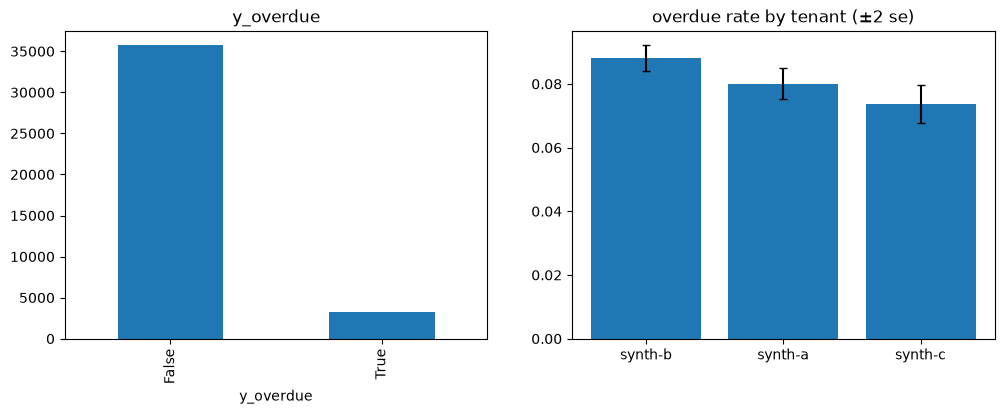

client_residency,local,tourist
tenant,,
synth-a,0.85,0.15
synth-b,0.72,0.28
synth-c,0.92,0.08


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
data["y_overdue"].value_counts().plot.bar(ax=ax[0], title="y_overdue")
r = rate_by("tenant")
ax[1].bar(r.index, r["rate"], yerr=2 * r["se"], capsize=3)
ax[1].set_title("overdue rate by tenant (±2 se)")
plt.show()
pd.crosstab(data["tenant"], data["client_residency"], normalize="index").round(2)

**Findings**
- 3,229 overdue of 38,953 checkouts: **8.29%**. The classes are imbalanced → evaluate with ROC-AUC and
  PR-AUC, not accuracy, and use a stratified split.
- Tenants differ (synth-b 8.8%, synth-a 8.0%, synth-c 7.4%), and the order follows the share of
  tourists (28% / 15% / 8%): the tenant effect is mostly a customer-mix effect.

## 3. Missing values

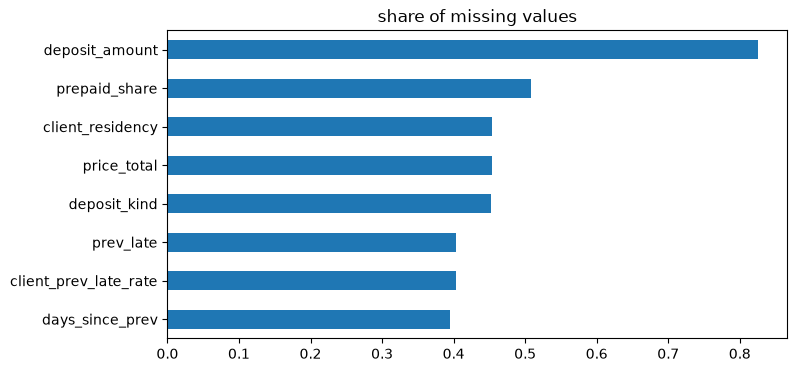

rate      n      se
                      missing                       
price_total           True     0.0842  17676  0.0021
                      False    0.0818  21277  0.0019
client_residency      True     0.0854  17681  0.0021
                      False    0.0808  21272  0.0019
client_prev_late_rate True     0.1047  15728  0.0024
                      False    0.0682  23225  0.0017

In [8]:
miss = data[FEATURES].isna().mean()
miss[miss > 0].sort_values().plot.barh(title="share of missing values", figsize=(8, 4))
plt.show()
pd.concat({c: rate_by(data[c].isna().rename("missing"))
           for c in ["price_total", "client_residency", "client_prev_late_rate"]})

**Findings** — three kinds of gaps:
- **The "Additional" block** (`deposit_kind`, `price_total`, `prepaid_amount`, `client_residency`, ~45%):
  an employee skipped the form. The overdue rate is the same with and without it (8.45% vs 8.19%), so
  the gap is random → keep NaN as its own "unknown" category instead of imputing it.
- **`deposit_amount`** (~83%): filled only for cash deposits — structural, not lost data.
- **Client history** (`client_prev_late_rate`, `prev_late`, `days_since_prev`, ~40%): the first visit to
  this tenant has no history. Here the gap *is* informative: 10.5% overdue without history vs 6.8% with
  it. `first_visit` already carries this signal.

## 4. Feature distributions

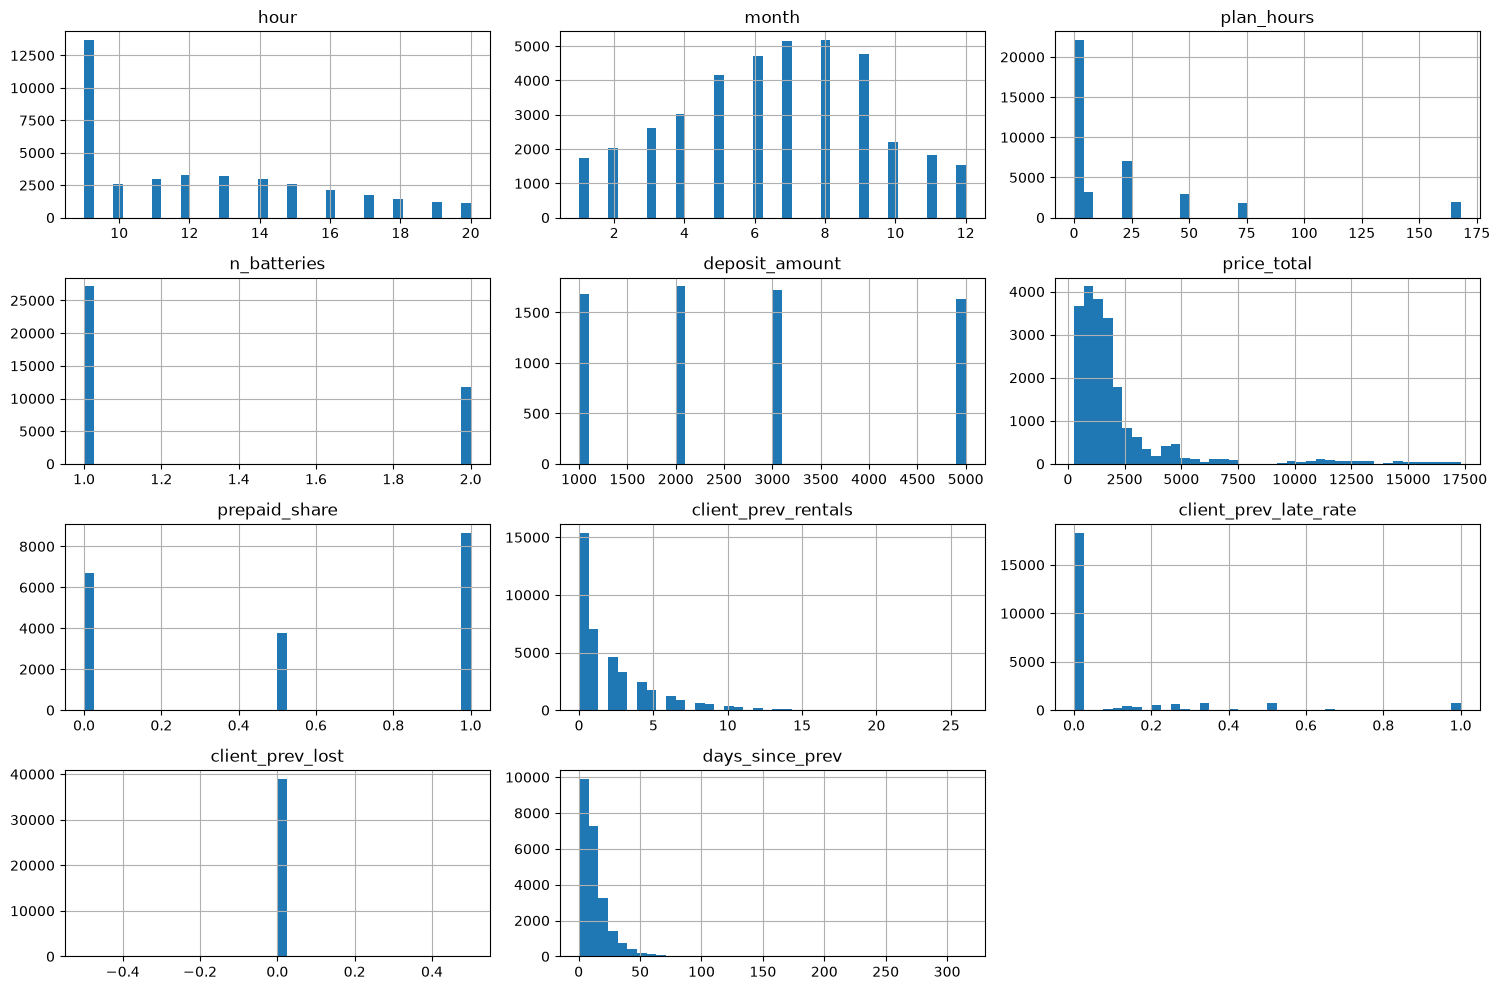

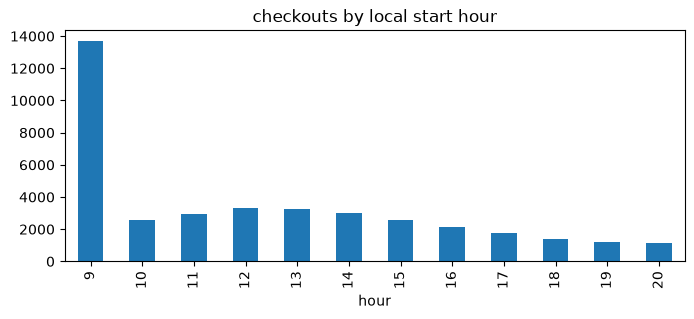

In [9]:
data[NUM].hist(bins=40, figsize=(15, 10))
plt.tight_layout()
plt.show()
data["hour"].value_counts().sort_index().plot.bar(title="checkouts by local start hour", figsize=(8, 3))
plt.show()

In [10]:
for c in CAT:
    display(data[c].value_counts(dropna=False).to_frame().T)

tenant,synth-b,synth-a,synth-c
count,19521,11867,7565


dow,5,6,1,0,3,4,2
count,6327,6246,5315,5285,5281,5265,5234


model,Cargo 500,Trail 350,Urban 250
count,14050,12894,12009


deposit_kind,NaN,none,cash,document
count,17612,7840,7526,5975


client_residency,NaN,local,tourist
count,17681,17113,4159


issued_by_employee_id,344a54b8-42c1-4a62-af48-e8d550fd9d3f,75523327-0262-4f73-9292-2f83ef8c485b,50f0fd0a-750c-4b75-8ccc-9bc2a53f8a28,655238a6-43ff-4011-bd1a-85dd506e5a9a,8fadc1a6-06cb-4fb3-9a1d-e644815ef6d1,17fc695a-07a0-4a6e-8822-e8f36c031199,23b8c1e9-3924-46de-beb1-3b9046685257,8b9d2434-e465-4150-bd9c-66b3ad3c2d6d,7e695d0d-8a3c-4b5e-801e-f1da45b1ed25,6e996e3e-e3b1-47fc-8a34-50fc9918ee46,176132ed-069f-44f1-8018-1c6e9a8cfa3c,b321bf21-4dd8-4b85-b04d-337677fc9703
count,4943,4870,4857,4851,3017,3004,2926,2920,1937,1898,1897,1833


**Findings**
- `plan_hours` takes a handful of values (1–6 hours, 1–3 days, 7 days) plus a tail of evening checkouts
  cut at closing → treat it as buckets rather than a continuous number.
- `price_total` is right-skewed → log-transform it for linear models.
- **35% of checkouts start at 09:00** (13,673 of 38,953) versus 1–3k for every other hour. This is a
  generator artifact: repeat visits are moved to the next opening time, so every visit that falls at
  night lands at 09:00. `hour` is distorted and confounded with repeat visits (09:00 has the lowest
  overdue rate, 6.8%).
- Categorical features are balanced; `issued_by_employee_id` has 12 levels (4 per tenant).

## 5. Feature vs target

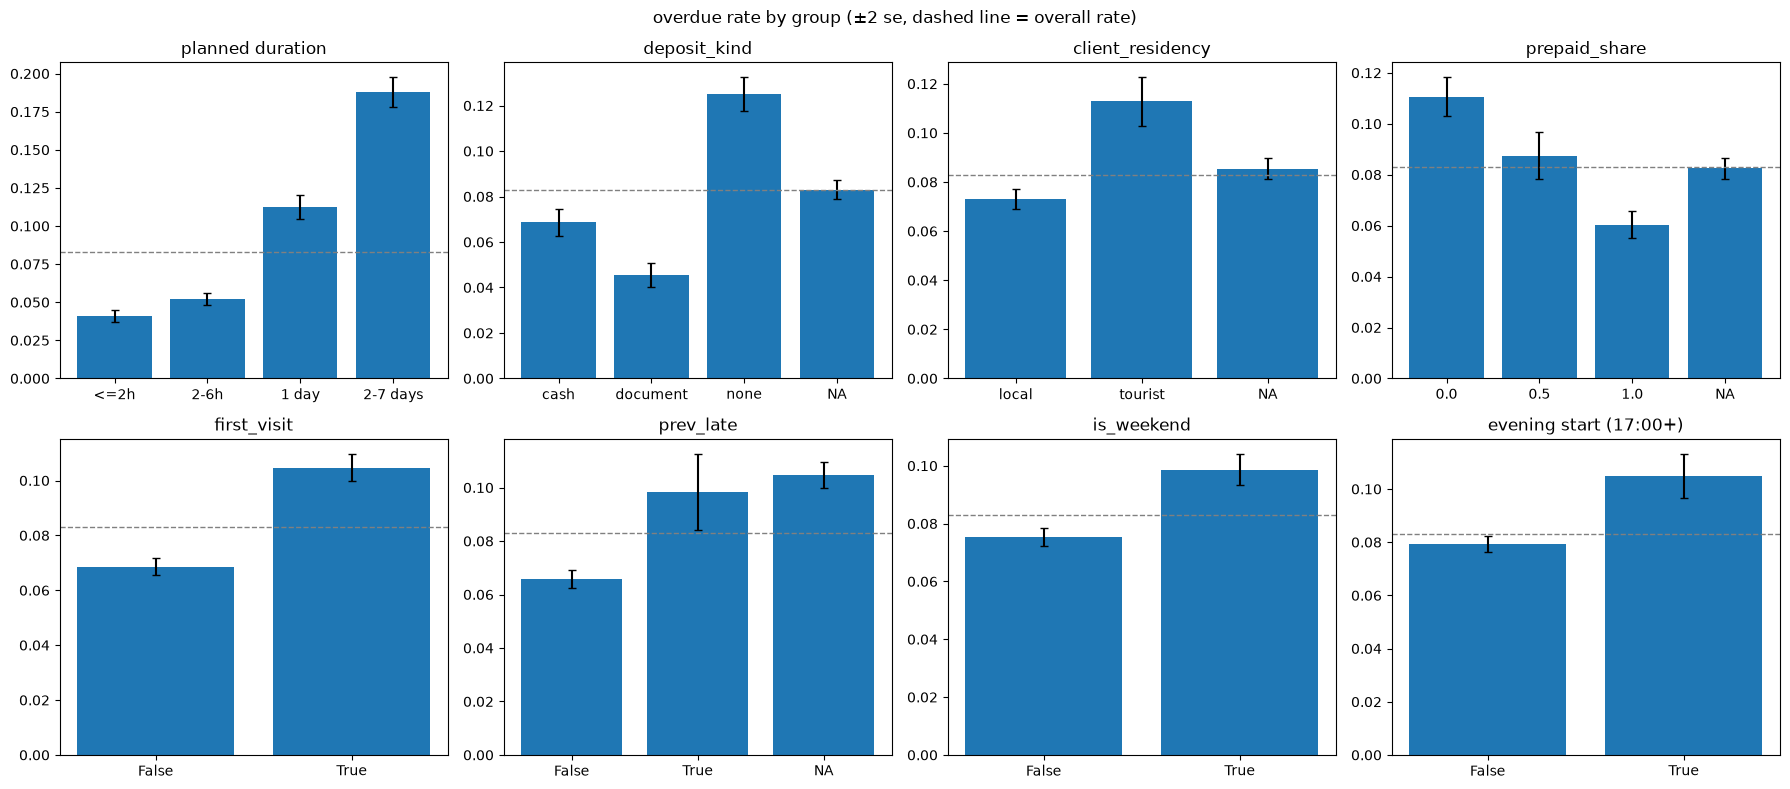

In [11]:
plan = pd.cut(data["plan_hours"], [-0.1, 2, 6, 24, 168],
              labels=["<=2h", "2-6h", "1 day", "2-7 days"]).rename("planned duration")
evening = (data["hour"] >= 17).rename("evening start (17:00+)")

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, [plan, "deposit_kind", "client_residency", "prepaid_share",
                               "first_visit", "prev_late", "is_weekend", evening]):
    r = rate_by(col).sort_index()
    ax.bar(r.index.astype("string").fillna("NA"), r["rate"], yerr=2 * r["se"], capsize=3)
    ax.axhline(data["y"].mean(), color="grey", ls="--", lw=1)
    ax.set_title(r.index.name)
plt.suptitle("overdue rate by group (±2 se, dashed line = overall rate)")
plt.tight_layout()
plt.show()

In [12]:
for col in CAT + BOOL + [plan, evening]:
    display(rate_by(col))

,rate,n,se
tenant,,,
synth-b,0.0881,19521,0.0020
synth-a,0.0801,11867,0.0025
synth-c,0.0738,7565,0.0030


,rate,n,se
dow,,,
6,0.1002,6246,0.0038
5,0.0972,6327,0.0037
4,0.0817,5265,0.0038
1,0.0788,5315,0.0037
2,0.0745,5234,0.0036
0,0.0711,5285,0.0035
3,0.0706,5281,0.0035


,rate,n,se
model,,,
Urban 250,0.0864,12009,0.0026
Trail 350,0.0827,12894,0.0024
Cargo 500,0.0801,14050,0.0023


,rate,n,se
deposit_kind,,,
none,0.1250,7840,0.0037
NaN,0.0830,17612,0.0021
cash,0.0686,7526,0.0029
document,0.0454,5975,0.0027


,rate,n,se
client_residency,,,
tourist,0.1128,4159,0.0049
NaN,0.0854,17681,0.0021
local,0.0730,17113,0.0020


...

,rate,n,se
block_missing,,,
True,0.0845,15258,0.0023
False,0.0819,23695,0.0018


,rate,n,se
first_visit,,,
True,0.1047,15402,0.0025
False,0.0686,23551,0.0016


,rate,n,se
prev_late,,,
<NA>,0.1047,15728,0.0024
True,0.0984,1758,0.0071
False,0.0657,21467,0.0017


,rate,n,se
planned duration,,,
2-7 days,0.1879,6614,0.0048
1 day,0.1125,7085,0.0038
2-6h,0.0520,14180,0.0019
<=2h,0.0408,11074,0.0019


,rate,n,se
evening start (17:00+),,,
True,0.1050,5516,0.0041
False,0.0793,33437,0.0015


**Findings** — overdue rate by group:

| Feature | Higher risk | Lower risk |
|---|---|---|
| planned duration | 2–7 days: 18.8% | ≤2 h: 4.1% |
| deposit | none: 12.5% | document: 4.5% |
| residency | tourist: 11.3% | local: 7.3% |
| prepaid share | 0: 11.1% | 1: 6.0% |
| first visit to the tenant | yes: 10.5% | no: 6.9% |
| previous checkout overdue | yes: 9.8% | no: 6.6% |
| weekend | yes: 9.9% | no: 7.5% |
| start hour | 17:00–20:00: 9.4–12.2% | 09:00: 6.8% |

`model` (8.0–8.6%) and `block_missing` (8.2% vs 8.5%) show no difference beyond noise.

## 6. Relations between features

In [13]:
data[NUM].corr("spearman").round(2)

,hour,month,plan_hours,n_batteries,deposit_amount,price_total,prepaid_share,client_prev_rentals,client_prev_late_rate,client_prev_lost,days_since_prev
hour,1.00,-0.01,-0.09,-0.00,0.03,-0.02,-0.01,-0.25,0.00,NaN,-0.02
month,-0.01,1.00,0.00,0.01,-0.02,0.01,0.00,0.05,0.02,NaN,0.02
plan_hours,-0.09,0.00,1.00,0.01,-0.01,0.91,0.01,-0.02,-0.01,NaN,0.01
n_batteries,-0.00,0.01,0.01,1.00,-0.00,-0.00,0.00,0.01,0.00,NaN,-0.00
deposit_amount,0.03,-0.02,-0.01,-0.00,1.00,-0.00,0.03,-0.02,0.03,NaN,-0.01
price_total,-0.02,0.01,0.91,-0.00,-0.00,1.00,0.01,0.01,0.00,NaN,0.01
prepaid_share,-0.01,0.00,0.01,0.00,0.03,0.01,1.00,0.01,0.00,NaN,-0.00
client_prev_rentals,-0.25,0.05,-0.02,0.01,-0.02,0.01,0.01,1.00,0.22,NaN,0.08
client_prev_late_rate,0.00,0.02,-0.01,0.00,0.03,0.00,0.00,0.22,1.00,NaN,0.00
client_prev_lost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
display(pd.crosstab(data["client_residency"], data["deposit_kind"], normalize="index").round(2))
rate_by(["deposit_kind", "client_residency"])["rate"].unstack()

deposit_kind,cash,document,none
client_residency,,,
local,0.35,0.25,0.40
tourist,0.36,0.40,0.23


client_residency,local,tourist,NaN
deposit_kind,,,
cash,0.0586,0.1040,0.0759
document,0.0347,0.0698,0.0509
none,0.1124,0.2023,0.1378
NaN,0.0625,0.1100,0.0846


**Findings**
- `price_total` vs `plan_hours`: Spearman 0.91. The price is mostly the duration, so the "price effect"
  is largely a duration effect. Keep `plan_hours`; keep the price only if it improves the model.
- Tourists leave a document more often (40% vs 25%), so deposit and residency are confounded. Within each
  group the order still holds — none > cash > document for locals (11.2 / 5.9 / 3.5%) and tourists
  (20.2 / 10.4 / 7.0%) — so both features carry their own signal.

## 7. Time

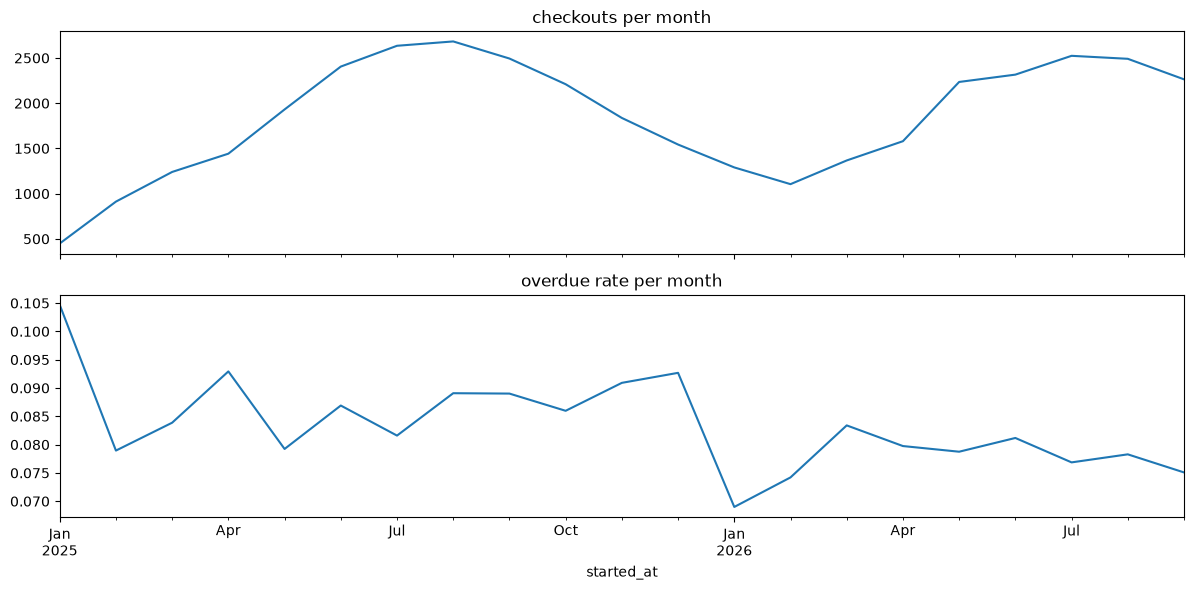

In [15]:
monthly = data.set_index("started_at").resample("MS")["y"].agg(["mean", "count"])
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
monthly["count"].plot(ax=ax[0], title="checkouts per month")
monthly["mean"].plot(ax=ax[1], title="overdue rate per month")
plt.tight_layout()
plt.show()

**Findings**
- Strong seasonality in volume: from ~450 checkouts in January 2025 (a partial month) to ~2,700 in
  August 2025.
- The monthly overdue rate fluctuates around 8.3% (6.9–10.5%).
- → Split by time (train on earlier months, validate on later ones). A random split would leak through the
  client-history features, which link rows of the same client.

## 8. Feature importance (one feature at a time)

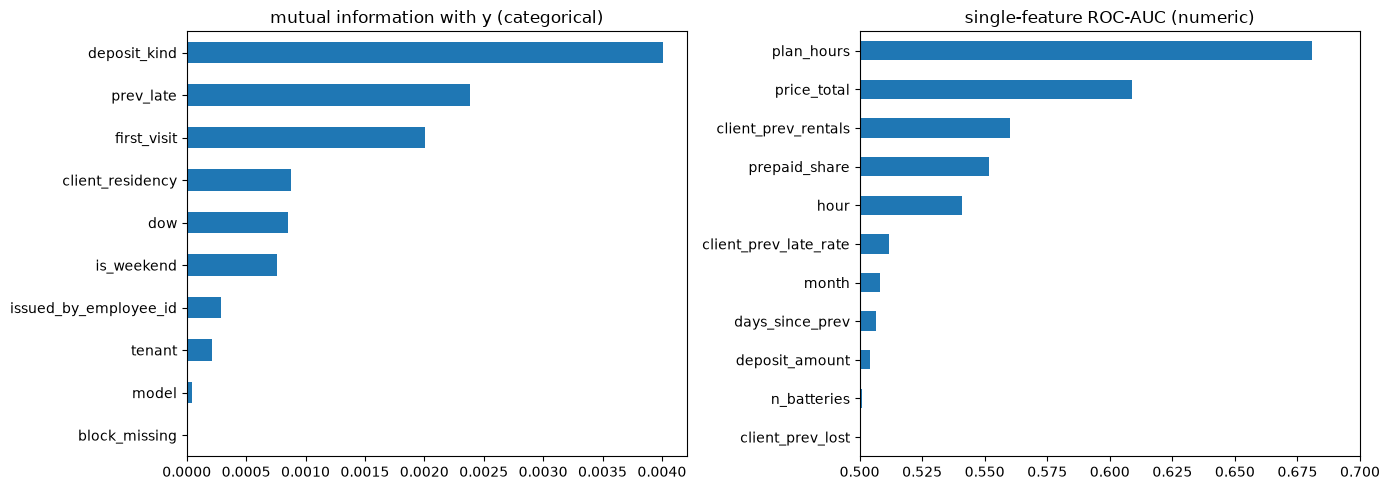

In [16]:
mi = pd.Series({c: mutual_info_score(data[c].astype("string").fillna("NA"), data["y"])
                for c in CAT + BOOL})
auc = pd.Series({c: roc_auc_score(data["y"], data[c].fillna(data[c].median())) for c in NUM})
auc = (auc - 0.5).abs() + 0.5  # the direction of the effect does not matter here

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
mi.sort_values().plot.barh(ax=ax[0], title="mutual information with y (categorical)")
auc.sort_values().plot.barh(ax=ax[1], title="single-feature ROC-AUC (numeric)", xlim=(0.5, 0.7))
plt.tight_layout()
plt.show()

**Findings**
- Strongest numeric feature: `plan_hours` (AUC 0.68), then `price_total` (0.61, mostly a copy of the
  duration).
- Strongest categorical features: `deposit_kind`, `prev_late`, `first_visit`.
- Decoys: `model` (MI 0.00004) and `issued_by_employee_id` (0.0003) are an order of magnitude below the
  real features → candidates for removal after checking on the model.
- `client_prev_late_rate` looks weak (0.51) only because its gaps were filled with the median; its
  missingness (first visit) is where the signal is.
- `client_prev_lost` and `n_batteries` (AUC 0.50) carry nothing.

## 9. Leakage check

In [17]:
LEAKY = {"ended_at", "outcome", "damaged", "closed_by_employee_id", "y_lost", "y_overdue"}
print("post-outcome columns among features:", sorted(LEAKY & set(FEATURES)) or "none")
print("strongest single numeric feature:", auc.idxmax(), round(auc.max(), 3))

post-outcome columns among features: none
strongest single numeric feature: plan_hours 0.681


No post-outcome columns among the features, and no single feature is suspiciously strong (best AUC 0.68).

## 10. Conclusions → decisions for the model

| Observation | Decision |
|---|---|
| Overdue rate 8.3%, imbalanced classes | ROC-AUC + PR-AUC; stratified split |
| Gaps in the "Additional" block are random | NaN → "unknown" category, no imputation |
| Missing history = first visit | keep `first_visit`; fill history gaps with a constant |
| `plan_hours` is discrete and the strongest feature | use buckets or one-hot |
| `price_total` ≈ `plan_hours` (Spearman 0.91) | keep only if it improves the model |
| `client_prev_lost`, `n_batteries` carry nothing | drop |
| `hour` distorted by the 09:00 spike | use an evening flag (start ≥ 17:00) instead of the raw hour |
| `model`, `issued_by_employee_id` ≈ 0 | check on the model, then drop |
| Seasonal volume, client history links rows | time-based train/validation split |